# Llegir les dades


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import geopandas as gpd
dataset_csv = pd.read_csv(r"../../Speculation-Map/Data/TouristicRentals/prova2025.csv",
                       index_col=0,dtype=object)

dataset_csv

,primer_cognom,nom_del_titular,ra_social_del_titular,cif,marca_tur_stica,sstt,total_estances,total_places,unitat_d_allotjament,categoria,...,tipus_establiment,cedula_d_habitabilitat,referencia_cadastral,bloc,escala,porta,pis,numero,nom_de_la_via,tipus_de_via
segon_cognom,,,,,,,,,,,,,,,,,,,,,
No aplica,No aplica,No aplica,FITEL S.L.,B60431533,Costa Barcelona,Barcelona,24,54,Apartaments,Sense categoritzar,...,Apartaments Turístics,No aplica,NaN,NaN,NaN,NaN,NaN,6,Bellavista,Carrer
No aplica,No aplica,No aplica,Camping el Berguedà SLU,B65693046,Pirineus,Catalunya Central,73,219,Unitats d'acampada,3 estrelles,...,Càmpings,No aplica,NaN,NaN,NaN,NaN,NaN,"KM 3,5",B-400,Carretera
No aplica,No aplica,No aplica,HCC REGENTE S.L.,B63508618,Barcelona,Barcelona,78,143,Habitació,4 estrelles,...,Hotels,No aplica,NaN,NaN,NaN,NaN,NaN,76,Catalunya,Rambla
No aplica,No aplica,No aplica,"OBA, S.L.",B58008780,Barcelona,Barcelona,8,12,Habitació,1 estrella,...,Hotels,No aplica,NaN,NaN,NaN,2,Entresol,8-10,Jaume I,Carrer
No aplica,No aplica,No aplica,"CAMPING GLORIA, SL",B58805078,Paisatges Barcelona,Catalunya Central,71,213,Unitats d'acampada,3 estrelles,...,Càmpings,No aplica,NaN,NaN,NaN,NaN,NaN,"KM 31,450",Vic-Olot,Carretera
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Monasterio,Pubill,Raquel,No aplica,No aplica,Pirineus,Lleida,4,8,Habitació,Sense categoritzar,...,Turisme rural,No aplica,NaN,NaN,NaN,NaN,NaN,"2, TOST",Major,Carrer
SENDRA,PONS,JOAN,No aplica,No aplica,Costa Daurada,Tarragona,4,11,Habitació,Sense categoritzar,...,Turisme rural,No aplica,NaN,NaN,NaN,NaN,NaN,SN,polígon 38 parcel.la 6,Polígon
Fierro,Sopena,Teresa,No aplica,No aplica,Pirineus,Lleida,2,4,Habitació,Sense categoritzar,...,Turisme rural,No aplica,NaN,NaN,NaN,NaN,NaN,s/n,Cal Casal,Carrer


# Comptar allotjaments turístics per codi de municipi

In [21]:
conteo_municipios = (
    dataset_csv["Codi Municipi (IDESCAT)"]
    .value_counts()
    .reset_index()
)
conteo_municipios.columns = ["Codi Municipi (IDESCAT)", "NombreEdificis"]


conteo_municipios.rename(columns={"Codi Municipi (IDESCAT)": "CODIMUNI"},inplace=True)
print(conteo_municipios)

    CODIMUNI  NombreEdificis
0     080193           11420
1     439057            7204
2     171523            5401
3     430385            3804
4     170470            3690
..       ...             ...
917   250740               1
918   251919               1
919   250411               1
920   250851               1
921   430347               1

[922 rows x 2 columns]


C:\Users\user\AppData\Local\Temp\ipykernel_20656\2903630879.py:9: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  conteo_municipios.rename(columns={"Codi Municipi (IDESCAT)": "CODIMUNI"},inplace=True)


# Merge del mapa amb el compteig d'habitatges

In [22]:
municipis=gpd.read_file("../../Speculation-Map/Data/CatalunyaMapMunicipalities.json").to_crs(25831)
municipis = municipis.merge(conteo_municipios, on="CODIMUNI", how="left", validate="one_to_one")

In [23]:
municipis

,CODIMUNI,NOMMUNI,CAPMUNI,AREAM5000,CODICOMAR,NOMCOMAR,CAPCOMAR,CODIVEGUE,NOMVEGUE,CAPVEGUE,CODIPROV,NOMPROV,CAPPROV,geometry,NombreEdificis
0,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((410315.774 4598888.867, 410075...",7.0
1,080023,Aguilar de Segarra,Aguilar de Segarra,43.2198,07,Bages,Manresa,07,Catalunya Central,*,08,Barcelona,Barcelona,"MULTIPOLYGON (((385155.598 4625034.944, 384697...",5.0
2,080039,Alella,Alella,9.6346,21,Maresme,Mataró,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((440348.026 4596213.927, 440338...",149.0
3,080044,Alpens,Alpens,13.7788,43,Lluçanès,Prats de Lluçanès,07,Catalunya Central,*,08,Barcelona,Barcelona,"MULTIPOLYGON (((425142.962 4665930.715, 424829...",15.0
4,080057,l'Ametlla del Vallès,l'Ametlla del Vallès,14.0885,41,Vallès Oriental,Granollers,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((436871.133 4617049.619, 436914...",31.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
942,439039,Camarles,Camarles,30.0157,09,Baix Ebre,Tortosa,05,Terres de l'Ebre,Tortosa,43,Tarragona,Tarragona,"MULTIPOLYGON (((301288.757 4521580.722, 301179...",64.0
943,439044,l'Aldea,l'Aldea,30.4743,09,Baix Ebre,Tortosa,05,Terres de l'Ebre,Tortosa,43,Tarragona,Tarragona,"MULTIPOLYGON (((298373.126 4520080.954, 298283...",31.0
944,439057,Salou,Salou,15.1248,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,43,Tarragona,Tarragona,"MULTIPOLYGON (((343971.449 4551180.512, 343522...",7204.0
945,439060,l'Ampolla,l'Ampolla,35.6196,09,Baix Ebre,Tortosa,05,Terres de l'Ebre,Tortosa,43,Tarragona,Tarragona,"MULTIPOLYGON (((305434.379 4524718.838, 305365...",688.0


# Mapa d'habitatges per municipi

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

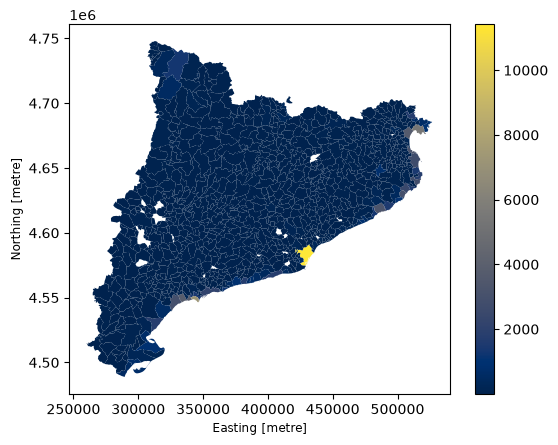

In [24]:

municipis.plot(column="NombreEdificis", cmap="cividis", legend=True)


# Llegir el dataset d'habitants

In [25]:
habitants = gpd.read_file("../../Speculation-Map/Data/Habitants.csv")
habitants


,YEAR,MUN,SEX,CONCEPT,status,value
0,2025,250019,M,POP,,83
1,2025,250019,F,POP,,79
2,2025,250019,TOTAL,POP,,162
3,2025,080018,M,POP,,6634
4,2025,080018,F,POP,,6573
...,...,...,...,...,...,...
2866,2025,430521,F,POP,,602
2867,2025,430521,TOTAL,POP,,1186
2868,2025,TOTAL,M,POP,,4006834
2869,2025,TOTAL,F,POP,,4117292


# Reordenem la taula i fem una copia del codi de municipi per a que no sigui un index, sino una columna

In [26]:
habitants1 = habitants.pivot(index="MUN",columns="SEX",values="value")
habitants1["MUN_COPY"] = habitants1.index
habitants1

SEX,F,M,TOTAL,MUN_COPY
MUN,,,,
080018,6573,6634,13207,080018
080023,134,159,293,080023
080039,5256,4995,10251,080039
080044,119,148,267,080044
080057,4698,4775,9473,080057
...,...,...,...,...
439044,2139,2586,4725,439044
439057,15296,15722,31018,439057
439060,1876,1933,3809,439060


# Fem que la columna de codi de municipi es digui igual que la del merge anterior

In [27]:
habitants1.rename(columns={"MUN_COPY": "CODIMUNI"},inplace=True)
habitants1

C:\Users\user\AppData\Local\Temp\ipykernel_20656\2698165327.py:1: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  habitants1.rename(columns={"MUN_COPY": "CODIMUNI"},inplace=True)


SEX,F,M,TOTAL,CODIMUNI
MUN,,,,
080018,6573,6634,13207,080018
080023,134,159,293,080023
080039,5256,4995,10251,080039
080044,119,148,267,080044
080057,4698,4775,9473,080057
...,...,...,...,...
439044,2139,2586,4725,439044
439057,15296,15722,31018,439057
439060,1876,1933,3809,439060


# Afegim la columna d'habitants a la llista

In [28]:
municipis_merged = municipis.merge(habitants1, on="CODIMUNI", how="left", validate="one_to_one")
municipis_merged

,CODIMUNI,NOMMUNI,CAPMUNI,AREAM5000,CODICOMAR,NOMCOMAR,CAPCOMAR,CODIVEGUE,NOMVEGUE,CAPVEGUE,CODIPROV,NOMPROV,CAPPROV,geometry,NombreEdificis,F,M,TOTAL
0,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((410315.774 4598888.867, 410075...",7.0,6573,6634,13207
1,080023,Aguilar de Segarra,Aguilar de Segarra,43.2198,07,Bages,Manresa,07,Catalunya Central,*,08,Barcelona,Barcelona,"MULTIPOLYGON (((385155.598 4625034.944, 384697...",5.0,134,159,293
2,080039,Alella,Alella,9.6346,21,Maresme,Mataró,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((440348.026 4596213.927, 440338...",149.0,5256,4995,10251
3,080044,Alpens,Alpens,13.7788,43,Lluçanès,Prats de Lluçanès,07,Catalunya Central,*,08,Barcelona,Barcelona,"MULTIPOLYGON (((425142.962 4665930.715, 424829...",15.0,119,148,267
4,080057,l'Ametlla del Vallès,l'Ametlla del Vallès,14.0885,41,Vallès Oriental,Granollers,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((436871.133 4617049.619, 436914...",31.0,4698,4775,9473
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
942,439039,Camarles,Camarles,30.0157,09,Baix Ebre,Tortosa,05,Terres de l'Ebre,Tortosa,43,Tarragona,Tarragona,"MULTIPOLYGON (((301288.757 4521580.722, 301179...",64.0,1689,1810,3499
943,439044,l'Aldea,l'Aldea,30.4743,09,Baix Ebre,Tortosa,05,Terres de l'Ebre,Tortosa,43,Tarragona,Tarragona,"MULTIPOLYGON (((298373.126 4520080.954, 298283...",31.0,2139,2586,4725
944,439057,Salou,Salou,15.1248,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,43,Tarragona,Tarragona,"MULTIPOLYGON (((343971.449 4551180.512, 343522...",7204.0,15296,15722,31018
945,439060,l'Ampolla,l'Ampolla,35.6196,09,Baix Ebre,Tortosa,05,Terres de l'Ebre,Tortosa,43,Tarragona,Tarragona,"MULTIPOLYGON (((305434.379 4524718.838, 305365...",688.0,1876,1933,3809


In [29]:
municipis_merged["TOTAL"]=pd.to_numeric(municipis_merged["TOTAL"], errors="coerce") #Ha calgut passar de string a float la columna TOTAL

# Creem una nova columna que sigui la fracció entre Habitatges/Habitants

In [30]:
municipis_merged["fraccio"] = municipis_merged["NombreEdificis"]/municipis_merged["TOTAL"]
municipis_merged

,CODIMUNI,NOMMUNI,CAPMUNI,AREAM5000,CODICOMAR,NOMCOMAR,CAPCOMAR,CODIVEGUE,NOMVEGUE,CAPVEGUE,CODIPROV,NOMPROV,CAPPROV,geometry,NombreEdificis,F,M,TOTAL,fraccio
0,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((410315.774 4598888.867, 410075...",7.0,6573,6634,13207,0.000530
1,080023,Aguilar de Segarra,Aguilar de Segarra,43.2198,07,Bages,Manresa,07,Catalunya Central,*,08,Barcelona,Barcelona,"MULTIPOLYGON (((385155.598 4625034.944, 384697...",5.0,134,159,293,0.017065
2,080039,Alella,Alella,9.6346,21,Maresme,Mataró,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((440348.026 4596213.927, 440338...",149.0,5256,4995,10251,0.014535
3,080044,Alpens,Alpens,13.7788,43,Lluçanès,Prats de Lluçanès,07,Catalunya Central,*,08,Barcelona,Barcelona,"MULTIPOLYGON (((425142.962 4665930.715, 424829...",15.0,119,148,267,0.056180
4,080057,l'Ametlla del Vallès,l'Ametlla del Vallès,14.0885,41,Vallès Oriental,Granollers,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((436871.133 4617049.619, 436914...",31.0,4698,4775,9473,0.003272
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
942,439039,Camarles,Camarles,30.0157,09,Baix Ebre,Tortosa,05,Terres de l'Ebre,Tortosa,43,Tarragona,Tarragona,"MULTIPOLYGON (((301288.757 4521580.722, 301179...",64.0,1689,1810,3499,0.018291
943,439044,l'Aldea,l'Aldea,30.4743,09,Baix Ebre,Tortosa,05,Terres de l'Ebre,Tortosa,43,Tarragona,Tarragona,"MULTIPOLYGON (((298373.126 4520080.954, 298283...",31.0,2139,2586,4725,0.006561
944,439057,Salou,Salou,15.1248,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,43,Tarragona,Tarragona,"MULTIPOLYGON (((343971.449 4551180.512, 343522...",7204.0,15296,15722,31018,0.232252
945,439060,l'Ampolla,l'Ampolla,35.6196,09,Baix Ebre,Tortosa,05,Terres de l'Ebre,Tortosa,43,Tarragona,Tarragona,"MULTIPOLYGON (((305434.379 4524718.838, 305365...",688.0,1876,1933,3809,0.180625


# Plotejem el mapa en funció de la columna fracció (afegim escala i orientació)

In [31]:
def add_scale_bar(ax, length_km=50, loc=(0.05, 0.002)):
    """Draw a scale bar of length_km on an Axes whose coordinates are in metres."""
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    x = x0 + loc[0] * (x1 - x0)
    y = y0 + loc[1] * (y1 - y0)
    ax.plot([x, x + length_km * 1000], [y, y], color="black", lw=3)
    ax.text(x + length_km * 500, y + 0.015 * (y1 - y0), f"{length_km} km", ha="center", va="bottom", fontsize=9)


def add_north_arrow(ax, loc=(0.93, 0.93)):
    ax.annotate("N", xy=loc, xytext=(loc[0], loc[1] - 0.1), xycoords="axes fraction",
                ha="center", va="center", fontsize=12, fontweight="bold",
                arrowprops={"arrowstyle": "-|>", "color": "black"})

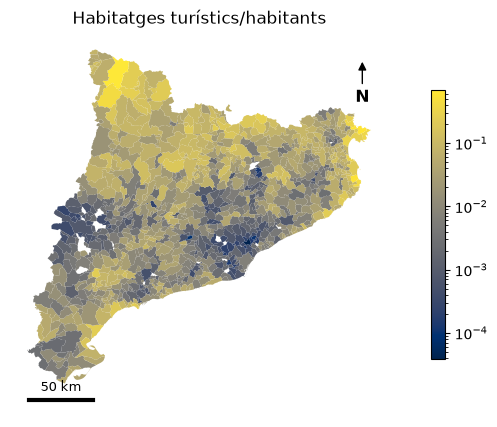

In [32]:
from matplotlib.colors import LogNorm # En escala logarítmica
fig, axs = plt.subplots(1, 1, figsize=(11, 5))
municipis_merged.plot(column="fraccio", cmap="cividis", norm=LogNorm(),legend=True, ax=axs,
         legend_kwds={"shrink": 0.7})
axs.set_title("Habitatges turístics/habitants")
axs.set_axis_off()
add_scale_bar(axs)
add_north_arrow(axs)
plt.show()

# Plotejem per quintils

In [33]:
municipis_merged["quintile"] = pd.qcut(municipis_merged["fraccio"], 5, labels=["lowest 20%", "2", "3", "4", "highest 20%"])

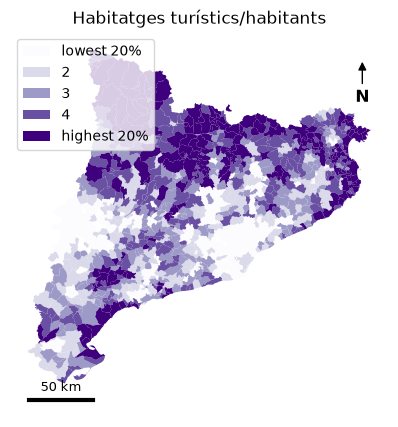

In [34]:
from matplotlib.colors import LogNorm
fig, axs = plt.subplots(1, 1, figsize=(11, 5))
municipis_merged.plot(column="quintile", cmap="Purples", norm=LogNorm(),legend=True, ax=axs)
axs.set_title("Habitatges turístics/habitants")
axs.set_axis_off()
axs.legend(loc='best')
add_scale_bar(axs)
add_north_arrow(axs)
plt.show()